Import Packages

In [9]:
from pathlib import Path
from collections import Counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, classification_report, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay, brier_score_loss,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

Import Data and Verify that they match the corresponding months

In [10]:
data_folder = Path(".")

# The six months we are studying
files = {
    1: "jan_T_ONTIME_REPORTING.csv",
    5: "may_T_ONTIME_REPORTING.csv",
    6: "june_T_ONTIME_REPORTING.csv",
    7: "july_T_ONTIME_REPORTING.csv",
    11: "nov_T_ONTIME_REPORTING.csv",
    12: "dec_T_ONTIME_REPORTING.csv"
}
files


# Check the month and year inside each CSV file
checks = []

for expected_month, filename in files.items():
    df_check = pd.read_csv(
        data_folder / filename,
        usecols=["YEAR", "MONTH"]
    )

    actual_months = sorted(df_check["MONTH"].unique().tolist())
    actual_years = sorted(df_check["YEAR"].unique().tolist())

    status = (
        "Correct"
        if actual_months == [expected_month]
        and actual_years == [2025]
        else "Incorrect"
    )

    checks.append({
        "File": filename,
        "Expected Month": expected_month,
        "Actual Month(s)": actual_months,
        "Rows": len(df_check),
        "Status": status
    })

pd.DataFrame(checks)


,File,Expected Month,Actual Month(s),Rows,Status
0,jan_T_ONTIME_REPORTING.csv,1,[1],539747,Correct
1,may_T_ONTIME_REPORTING.csv,5,[5],605648,Correct
2,june_T_ONTIME_REPORTING.csv,6,[6],611575,Correct
3,july_T_ONTIME_REPORTING.csv,7,[7],631428,Correct
4,nov_T_ONTIME_REPORTING.csv,11,[11],570550,Correct
5,dec_T_ONTIME_REPORTING.csv,12,[12],582304,Correct


Combine the data into one dataset

In [11]:

# Columns needed for our analysis
columns = [
    "YEAR",
    "MONTH",
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "CANCELLED",
    "DIVERTED",
    "ARR_DEL15"
]

# Create an empty list to store each month's data
dataframes = []

# Load each monthly CSV file
for expected_month, filename in files.items():
    df_month = pd.read_csv(
        data_folder / filename,
        usecols=lambda col: col in columns
    )

    # Prevent incorrectly labeled months from being combined
    if not (
        df_month["YEAR"].eq(2025).all()
        and df_month["MONTH"].eq(expected_month).all()
    ):
        raise ValueError(f"Incorrect month or year in {filename}")

    dataframes.append(df_month)
    print(f"Loaded {filename}: {len(df_month):,} flights")

# Combine all months into one DataFrame
flights = pd.concat(dataframes, ignore_index=True)

print(f"\nTotal flights: {len(flights):,}")

# Display the first five rows
display(flights.head())

# Check dimensions
print("Dataset shape:", flights.shape)

# Check column names and data types
flights.info()

# Count flights in each month
monthly_counts = flights.groupby("MONTH").size()

print("Flights per month:")
display(monthly_counts)


Loaded jan_T_ONTIME_REPORTING.csv: 539,747 flights
Loaded may_T_ONTIME_REPORTING.csv: 605,648 flights
Loaded june_T_ONTIME_REPORTING.csv: 611,575 flights
Loaded july_T_ONTIME_REPORTING.csv: 631,428 flights
Loaded nov_T_ONTIME_REPORTING.csv: 570,550 flights
Loaded dec_T_ONTIME_REPORTING.csv: 582,304 flights

Total flights: 3,541,252


,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025,1,1,3,1/1/2025 12:00:00 AM,AA,SFO,JFK,1030,1912,0.0,0.0,0.0,342.0,2586.0
1,2025,1,1,3,1/1/2025 12:00:00 AM,AA,JFK,SFO,600,940,0.0,0.0,0.0,400.0,2586.0
2,2025,1,1,3,1/1/2025 12:00:00 AM,AA,SAT,CLT,819,1206,0.0,0.0,0.0,167.0,1095.0
3,2025,1,1,3,1/1/2025 12:00:00 AM,AA,JFK,LAX,2100,29,0.0,0.0,0.0,389.0,2475.0
4,2025,1,1,3,1/1/2025 12:00:00 AM,AA,BOS,LAX,801,1140,0.0,0.0,0.0,399.0,2611.0


Dataset shape: (3541252, 15)
<class 'pandas.DataFrame'>
RangeIndex: 3541252 entries, 0 to 3541251
Data columns (total 15 columns):
 #   Column             Dtype  
---  ------             -----  
 0   YEAR               int64  
 1   MONTH              int64  
 2   DAY_OF_MONTH       int64  
 3   DAY_OF_WEEK        int64  
 4   FL_DATE            str    
 5   OP_UNIQUE_CARRIER  str    
 6   ORIGIN             str    
 7   DEST               str    
 8   CRS_DEP_TIME       int64  
 9   CRS_ARR_TIME       int64  
 10  ARR_DEL15          float64
 11  CANCELLED          float64
 12  DIVERTED           float64
 13  CRS_ELAPSED_TIME   float64
 14  DISTANCE           float64
dtypes: float64(5), int64(6), str(4)
memory usage: 503.3 MB
Flights per month:


MONTH
1     539747
5     605648
6     611575
7     631428
11    570550
12    582304
dtype: int64

Check for missingness

In [12]:
# Check missing values in each column
missing_values = flights.isnull().sum()

# Calculate percentage of missing values
missing_percent = (flights.isnull().mean() * 100).round(2)

# Create summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Values,Missing Percentage
ARR_DEL15,81906,2.31
MONTH,0,0.00
YEAR,0,0.00
DAY_OF_WEEK,0,0.00
FL_DATE,0,0.00
OP_UNIQUE_CARRIER,0,0.00
DAY_OF_MONTH,0,0.00
ORIGIN,0,0.00
DEST,0,0.00
CRS_DEP_TIME,0,0.00


Removed Cancelled and Diverted flights

In [13]:

# Convert relevant columns to numeric
numeric_columns = [
    "CANCELLED",
    "DIVERTED",
    "ARR_DEL15",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
]

for col in numeric_columns:
    flights[col] = pd.to_numeric(
        flights[col], errors="coerce"
    )

# Record original size
original_count = len(flights)

# Keep flights that were not cancelled or diverted
clean_flights = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0)
].copy()

# Keep flights with valid arrival delay outcomes
clean_flights = clean_flights[
    clean_flights["ARR_DEL15"].isin([0, 1])
].copy()

# Make the target variable an integer
clean_flights["ARR_DEL15"] = (
    clean_flights["ARR_DEL15"].astype(int)
)

print(f"Original flights: {original_count:,}")
print(f"Cleaned flights: {len(clean_flights):,}")
print(f"Removed flights: {original_count - len(clean_flights):,}")


Original flights: 3,541,252
Cleaned flights: 3,459,346
Removed flights: 81,906


Verify Clean data

In [14]:

# Check the remaining months
print("Flights per month:")
display(clean_flights.groupby("MONTH").size())

# Check target values
print("\nArrival delay classification:")
display(clean_flights["ARR_DEL15"].value_counts())

# Check remaining missing values
print("\nRemaining missing values:")
display(
    clean_flights.isnull().sum().sort_values(
        ascending=False
    )
)


Flights per month:


MONTH
1     522269
5     597574
6     599472
7     612811
11    555296
12    571924
dtype: int64


Arrival delay classification:


ARR_DEL15
0    2606478
1     852868
Name: count, dtype: int64


Remaining missing values:


YEAR                 0
MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
FL_DATE              0
OP_UNIQUE_CARRIER    0
ORIGIN               0
DEST                 0
CRS_DEP_TIME         0
CRS_ARR_TIME         0
ARR_DEL15            0
CANCELLED            0
DIVERTED             0
CRS_ELAPSED_TIME     0
DISTANCE             0
dtype: int64

Analyze the delayed flights

Flight delay distribution:


On Time (<15 min late)    75.35
Delayed (15+ min late)    24.65
Name: proportion, dtype: float64

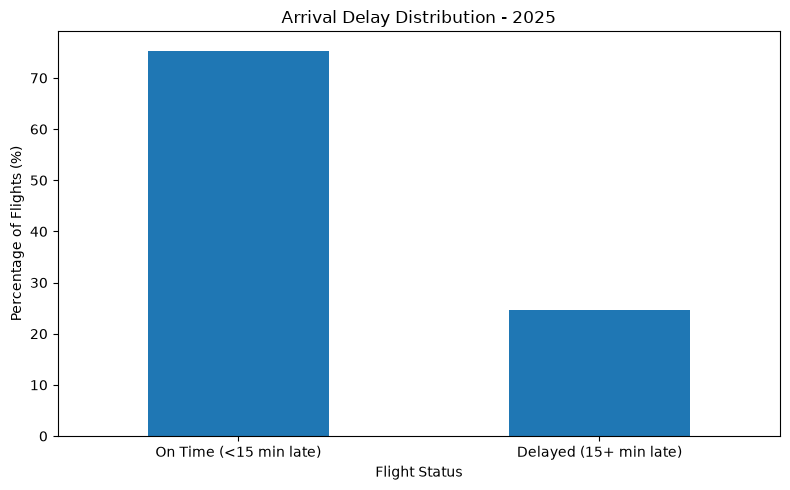

In [15]:

# Calculate percentage of delayed and on-time flights
delay_distribution = (
    clean_flights["ARR_DEL15"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

delay_distribution.index = [
    "On Time (<15 min late)",
    "Delayed (15+ min late)"
]

print("Flight delay distribution:")
display(delay_distribution.round(2))

# Visualize the distribution
plt.figure(figsize=(8, 5))

delay_distribution.plot(kind="bar")

plt.title("Arrival Delay Distribution - 2025")
plt.xlabel("Flight Status")
plt.ylabel("Percentage of Flights (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Select features to predict >15 minute delays

In [16]:

# Create a copy for modeling
model_data = clean_flights.copy()

# Convert scheduled departure time into departure hour
model_data["DEP_HOUR"] = (
    model_data["CRS_DEP_TIME"] // 100
) % 24

# Select predictor variables
features = [
    "DAY_OF_WEEK",
    "DAY_OF_MONTH",
    "DEP_HOUR",
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "DISTANCE",
    "CRS_ELAPSED_TIME"
]

# Define features (X) and target (y)
X = model_data[features]
y = model_data["ARR_DEL15"]

print("Features:", X.shape)
print("Target:", y.shape)

display(X.head())


Features: (3459346, 8)
Target: (3459346,)


,DAY_OF_WEEK,DAY_OF_MONTH,DEP_HOUR,OP_UNIQUE_CARRIER,ORIGIN,DEST,DISTANCE,CRS_ELAPSED_TIME
0,3,1,10,AA,SFO,JFK,2586.0,342.0
1,3,1,6,AA,JFK,SFO,2586.0,400.0
2,3,1,8,AA,SAT,CLT,1095.0,167.0
3,3,1,21,AA,JFK,LAX,2475.0,389.0
4,3,1,8,AA,BOS,LAX,2611.0,399.0


Split, Train, Validate, and Test data

In [17]:

# Split data by month
train = model_data[
    model_data["MONTH"].isin([1, 5, 6, 7])
]

val = model_data[
    model_data["MONTH"] == 11
]

test = model_data[
    model_data["MONTH"] == 12
]

# Separate features and target for each set
X_train = train[features]
y_train = train["ARR_DEL15"]

X_val = val[features]
y_val = val["ARR_DEL15"]

X_test = test[features]
y_test = test["ARR_DEL15"]

# Check dataset sizes
print("Training flights:", len(X_train))
print("Validation flights:", len(X_val))
print("Testing flights:", len(X_test))


Training flights: 2332126
Validation flights: 555296
Testing flights: 571924


Process Variables (One-Hot encoding for categorical variables)

In [18]:
# Numerical features
numeric_features = [
    "DAY_OF_WEEK",
    "DAY_OF_MONTH",
    "DEP_HOUR",
    "DISTANCE",
    "CRS_ELAPSED_TIME"
]

# Categorical features
categorical_features = [
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST"
]

# Handle missing numerical values
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Handle categorical variables
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


Prepare data for modeling

In [19]:

# Verify the training, validation, and testing sets
for name, X_set, y_set in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    print(f"\n{name} set:")
    print("Shape:", X_set.shape)
    print("Delay rate:", round(y_set.mean() * 100, 2), "%")
    print("Missing predictor values:", X_set.isna().sum().sum())



Training set:
Shape: (2332126, 8)
Delay rate: 25.11 %
Missing predictor values: 0

Validation set:
Shape: (555296, 8)
Delay rate: 20.56 %
Missing predictor values: 0

Testing set:
Shape: (571924, 8)
Delay rate: 26.77 %
Missing predictor values: 0


Create the Random Forest Model, then Train the model

In [20]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=20,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")


Random Forest model created successfully!


In [21]:

# Sample up to 200,000 training flights
sample_size = min(200000, len(X_train))

X_train_sample = X_train.sample(
    n=sample_size,
    random_state=42
)

# Match target values to sampled flights
y_train_sample = y_train.loc[X_train_sample.index]

# Train the Random Forest
rf_model.fit(X_train_sample, y_train_sample)

print("Random Forest training completed!")
print(f"Training samples: {len(X_train_sample):,}")


Random Forest training completed!
Training samples: 200,000


Generate Predictions

In [22]:

# Sample validation flights
val_size = min(75000, len(X_val))

X_val_sample = X_val.sample(
    n=val_size,
    random_state=42
)

y_val_sample = y_val.loc[X_val_sample.index]

# Predict whether flights are delayed
rf_predictions = rf_model.predict(X_val_sample)

# Predict probability of a delay
rf_probabilities = rf_model.predict_proba(
    X_val_sample
)[:, 1]

print("Predictions generated successfully!")

# Show the first 10 predictions
results = pd.DataFrame({
    "Actual": y_val_sample.values,
    "Predicted": rf_predictions,
    "Delay Probability": rf_probabilities
})

display(results.head(10))


Predictions generated successfully!


,Actual,Predicted,Delay Probability
0,0,0,0.294473
1,0,0,0.220429
2,0,0,0.284378
3,0,0,0.307657
4,0,0,0.218743
5,0,0,0.226511
6,0,0,0.202266
7,0,0,0.202359
8,0,0,0.188735
9,0,0,0.191898


Evaluate and Interpret the Random Forest Model

In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

# Calculate metrics
rf_accuracy = accuracy_score(
    y_val_sample, rf_predictions
)

rf_precision = precision_score(
    y_val_sample, rf_predictions, zero_division=0
)

rf_recall = recall_score(
    y_val_sample, rf_predictions, zero_division=0
)

rf_f1 = f1_score(
    y_val_sample, rf_predictions, zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_val_sample, rf_probabilities
)

rf_pr_auc = average_precision_score(
    y_val_sample, rf_probabilities
)

# Display metrics
rf_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision (PR-AUC)"
    ],
    "Score": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_roc_auc,
        rf_pr_auc
    ]
})

display(rf_metrics.round(4))

print(classification_report(
    y_val_sample,
    rf_predictions,
    target_names=["On Time", "Delayed"],
    zero_division=0
))


,Metric,Score
0,Accuracy,0.7944
1,Precision,0.0000
2,Recall,0.0000
3,F1 Score,0.0000
4,ROC-AUC,0.6310
5,Average Precision (PR-AUC),0.2985


              precision    recall  f1-score   support

     On Time       0.79      1.00      0.89     59578
     Delayed       0.00      0.00      0.00     15422

    accuracy                           0.79     75000
   macro avg       0.40      0.50      0.44     75000
weighted avg       0.63      0.79      0.70     75000



Confusion Matrix

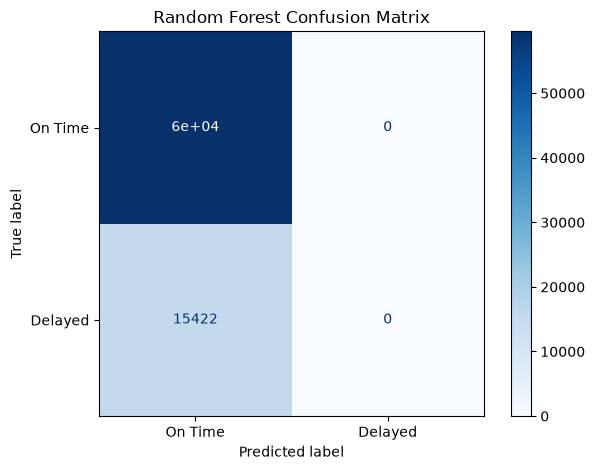

In [24]:

# Create confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val_sample,
    rf_predictions,
    display_labels=["On Time", "Delayed"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


Identify the Most influential factors

DEP_HOUR and DAY_OF_WEEK are the 1st and 2nd strongest predictors, respectfully. 

,Feature,Importance
2,DEP_HOUR,0.074234
0,DAY_OF_WEEK,0.017038
4,ORIGIN,0.007208
3,OP_UNIQUE_CARRIER,0.006150
5,DEST,0.001867
1,DAY_OF_MONTH,0.000548
6,DISTANCE,-0.000251
7,CRS_ELAPSED_TIME,-0.000286


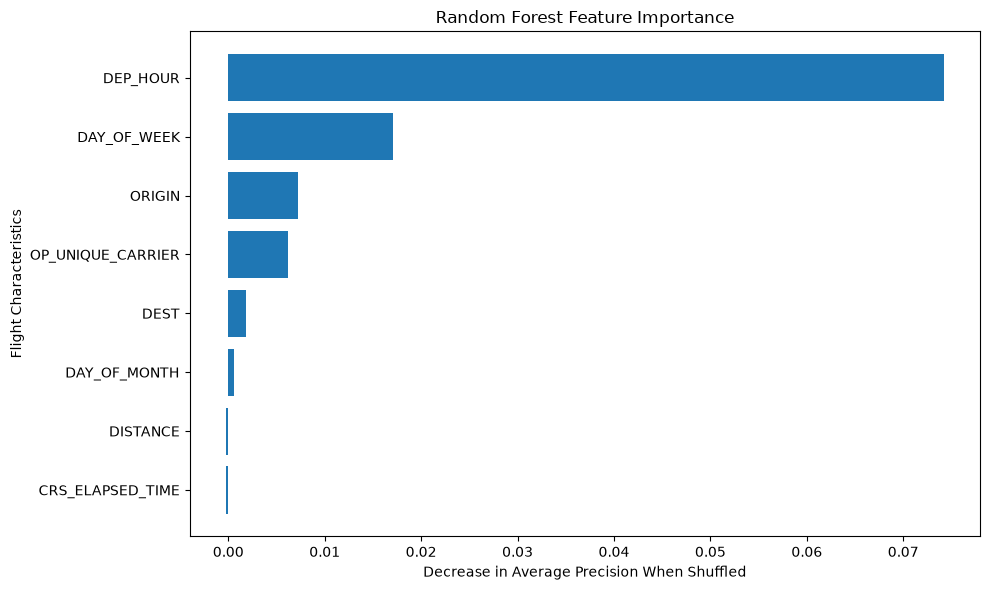

In [25]:

from sklearn.inspection import permutation_importance

# Use a smaller validation sample for interpretation
X_importance = X_val_sample.sample(
    n=min(3000, len(X_val_sample)),
    random_state=42
)

y_importance = y_val_sample.loc[X_importance.index]

# Calculate feature importance
importance = permutation_importance(
    rf_model,
    X_importance,
    y_importance,
    n_repeats=3,
    random_state=42,
    scoring="average_precision",
    n_jobs=1
)

# Create a table
feature_importance = pd.DataFrame({
    "Feature": X_importance.columns,
    "Importance": importance.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Decrease in Average Precision When Shuffled")
plt.ylabel("Flight Characteristics")

plt.tight_layout()
plt.show()

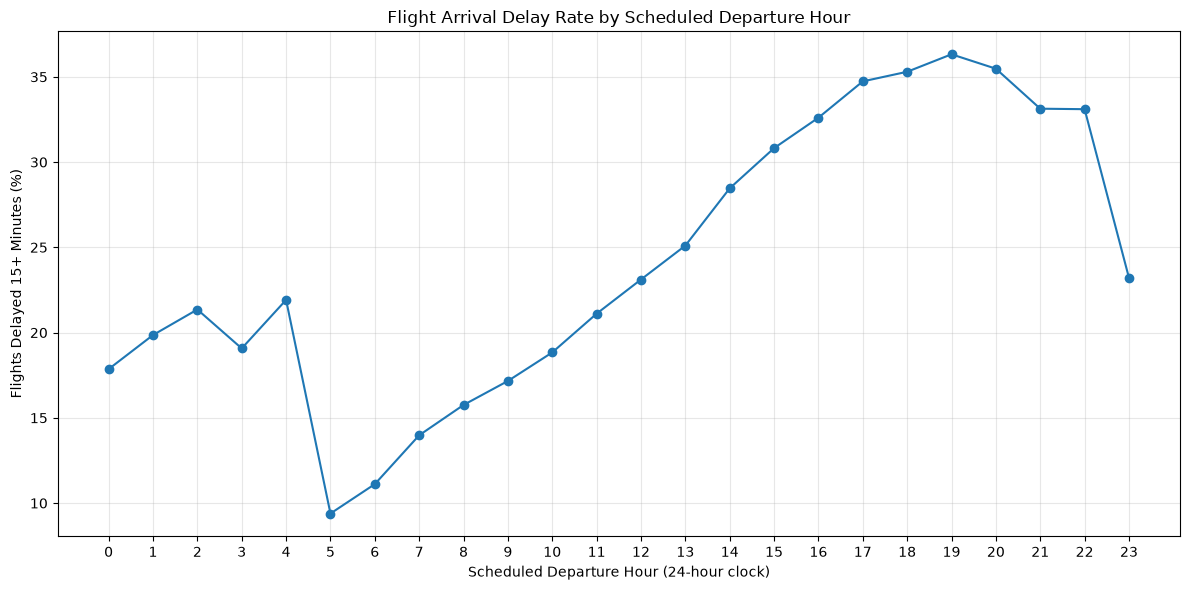

In [26]:
# Calculate the percentage of delayed flights by departure hour
hourly_delays = (
    model_data.groupby("DEP_HOUR")["ARR_DEL15"]
    .mean() * 100
)

# Plot the results
plt.figure(figsize=(12, 6))

hourly_delays.plot(
    kind="line",
    marker="o"
)

plt.title("Flight Arrival Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour (24-hour clock)")
plt.ylabel("Flights Delayed 15+ Minutes (%)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()

# Data Update (Delay Variables)

In [32]:
### Check CSV Files

from pathlib import Path

# Folder containing your CSV files
data_folder = Path("data")

# The six months we are studying
files = {
    1: "jan_T_ONTIME_REPORTING.csv",
    5: "may_T_ONTIME_REPORTING.csv",
    6: "june_T_ONTIME_REPORTING.csv",
    7: "july_T_ONTIME_REPORTING.csv",
    11: "nov_T_ONTIME_REPORTING.csv",
    12: "dec_T_ONTIME_REPORTING.csv"
}


# Check the month and year inside each CSV file
checks = []

for expected_month, filename in files.items():
    df_check = pd.read_csv(
        data_folder / filename,
        usecols=["YEAR", "MONTH"]
    )

    actual_months = sorted(df_check["MONTH"].unique().tolist())
    actual_years = sorted(df_check["YEAR"].unique().tolist())

    status = (
        "Correct"
        if actual_months == [expected_month]
        and actual_years == [2025]
        else "Incorrect"
    )

    checks.append({
        "File": filename,
        "Expected Month": expected_month,
        "Actual Month(s)": actual_months,
        "Rows": len(df_check),
        "Status": status
    })

pd.DataFrame(checks)


,File,Expected Month,Actual Month(s),Rows,Status
0,jan_T_ONTIME_REPORTING.csv,1,[1],539747,Correct
1,may_T_ONTIME_REPORTING.csv,5,[5],605648,Correct
2,june_T_ONTIME_REPORTING.csv,6,[6],611575,Correct
3,july_T_ONTIME_REPORTING.csv,7,[7],631428,Correct
4,nov_T_ONTIME_REPORTING.csv,11,[11],570550,Correct
5,dec_T_ONTIME_REPORTING.csv,12,[12],582304,Correct


### Combine all the data

In [33]:

# Columns needed for our analysis
columns = [
    "YEAR",
    "MONTH",
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "CANCELLED",
    "DIVERTED",
    "ARR_DEL15"
]

# Create an empty list to store each month's data
dataframes = []

# Load each monthly CSV file
for expected_month, filename in files.items():
    df_month = pd.read_csv(
        data_folder / filename,
        usecols=lambda col: col in columns
    )

    # Prevent incorrectly labeled months from being combined
    if not (
        df_month["YEAR"].eq(2025).all()
        and df_month["MONTH"].eq(expected_month).all()
    ):
        raise ValueError(f"Incorrect month or year in {filename}")

    dataframes.append(df_month)
    print(f"Loaded {filename}: {len(df_month):,} flights")

# Combine all months into one DataFrame
flights = pd.concat(dataframes, ignore_index=True)

print(f"\nTotal flights: {len(flights):,}")


Loaded jan_T_ONTIME_REPORTING.csv: 539,747 flights
Loaded may_T_ONTIME_REPORTING.csv: 605,648 flights
Loaded june_T_ONTIME_REPORTING.csv: 611,575 flights
Loaded july_T_ONTIME_REPORTING.csv: 631,428 flights
Loaded nov_T_ONTIME_REPORTING.csv: 570,550 flights
Loaded dec_T_ONTIME_REPORTING.csv: 582,304 flights

Total flights: 3,541,252


### New Data Information

In [34]:

# Display the first five rows
display(flights.head())

# Check dimensions
print("Dataset shape:", flights.shape)

# Check column names and data types
flights.info()


# Count flights in each month
monthly_counts = flights.groupby("MONTH").size()

print("Flights per month:")
display(monthly_counts)


,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025,1,1,3,1/1/2025 12:00:00 AM,AA,SFO,JFK,1030,1912,0.0,0.0,0.0,342.0,2586.0
1,2025,1,1,3,1/1/2025 12:00:00 AM,AA,JFK,SFO,600,940,0.0,0.0,0.0,400.0,2586.0
2,2025,1,1,3,1/1/2025 12:00:00 AM,AA,SAT,CLT,819,1206,0.0,0.0,0.0,167.0,1095.0
3,2025,1,1,3,1/1/2025 12:00:00 AM,AA,JFK,LAX,2100,29,0.0,0.0,0.0,389.0,2475.0
4,2025,1,1,3,1/1/2025 12:00:00 AM,AA,BOS,LAX,801,1140,0.0,0.0,0.0,399.0,2611.0


Dataset shape: (3541252, 15)
<class 'pandas.DataFrame'>
RangeIndex: 3541252 entries, 0 to 3541251
Data columns (total 15 columns):
 #   Column             Dtype  
---  ------             -----  
 0   YEAR               int64  
 1   MONTH              int64  
 2   DAY_OF_MONTH       int64  
 3   DAY_OF_WEEK        int64  
 4   FL_DATE            str    
 5   OP_UNIQUE_CARRIER  str    
 6   ORIGIN             str    
 7   DEST               str    
 8   CRS_DEP_TIME       int64  
 9   CRS_ARR_TIME       int64  
 10  ARR_DEL15          float64
 11  CANCELLED          float64
 12  DIVERTED           float64
 13  CRS_ELAPSED_TIME   float64
 14  DISTANCE           float64
dtypes: float64(5), int64(6), str(4)
memory usage: 503.3 MB
Flights per month:


MONTH
1     539747
5     605648
6     611575
7     631428
11    570550
12    582304
dtype: int64

### Clean Data

,Missing Values,Missing Percentage
ARR_DEL15,81906,2.31
MONTH,0,0.00
YEAR,0,0.00
DAY_OF_WEEK,0,0.00
FL_DATE,0,0.00
OP_UNIQUE_CARRIER,0,0.00
DAY_OF_MONTH,0,0.00
ORIGIN,0,0.00
DEST,0,0.00
CRS_DEP_TIME,0,0.00


Original flights: 3,541,252
Cleaned flights: 3,459,346
Removed flights: 81,906
Flights per month:


MONTH
1     522269
5     597574
6     599472
7     612811
11    555296
12    571924
dtype: int64


Arrival delay classification:


ARR_DEL15
0    2606478
1     852868
Name: count, dtype: int64


Remaining missing values:


YEAR                 0
MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
FL_DATE              0
OP_UNIQUE_CARRIER    0
ORIGIN               0
DEST                 0
CRS_DEP_TIME         0
CRS_ARR_TIME         0
ARR_DEL15            0
CANCELLED            0
DIVERTED             0
CRS_ELAPSED_TIME     0
DISTANCE             0
dtype: int64

Flight delay distribution:


On Time (<15 min late)    75.35
Delayed (15+ min late)    24.65
Name: proportion, dtype: float64

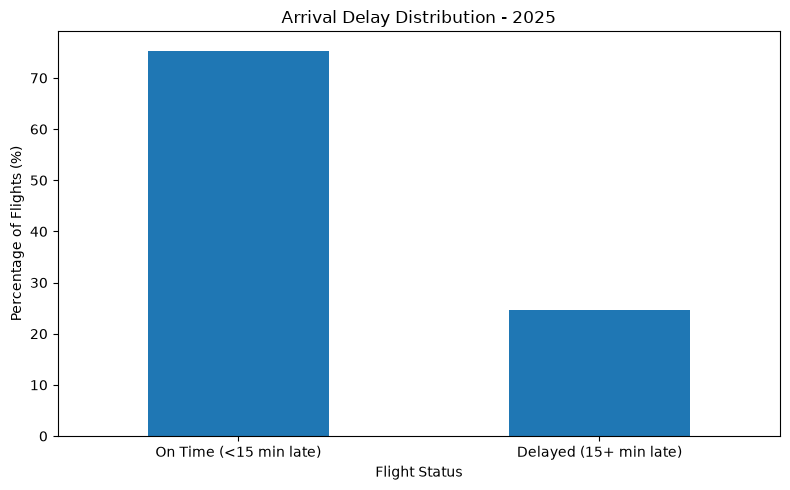

In [36]:

# Check missing values in each column
missing_values = flights.isnull().sum()

# Calculate percentage of missing values
missing_percent = (flights.isnull().mean() * 100).round(2)

# Create summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))


# Convert relevant columns to numeric
numeric_columns = [
    "CANCELLED",
    "DIVERTED",
    "ARR_DEL15",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
]

for col in numeric_columns:
    flights[col] = pd.to_numeric(
        flights[col], errors="coerce"
    )

# Record original size
original_count = len(flights)

# Keep flights that were not cancelled or diverted
clean_flights = flights[
    (flights["CANCELLED"] == 0) &
    (flights["DIVERTED"] == 0)
].copy()

# Keep flights with valid arrival delay outcomes
clean_flights = clean_flights[
    clean_flights["ARR_DEL15"].isin([0, 1])
].copy()

# Make the target variable an integer
clean_flights["ARR_DEL15"] = (
    clean_flights["ARR_DEL15"].astype(int)
)

print(f"Original flights: {original_count:,}")
print(f"Cleaned flights: {len(clean_flights):,}")
print(f"Removed flights: {original_count - len(clean_flights):,}")


# Check the remaining months
print("Flights per month:")
display(clean_flights.groupby("MONTH").size())

# Check target values
print("\nArrival delay classification:")
display(clean_flights["ARR_DEL15"].value_counts())

# Check remaining missing values
print("\nRemaining missing values:")
display(
    clean_flights.isnull().sum().sort_values(
        ascending=False
    )
)


# Calculate percentage of delayed and on-time flights
delay_distribution = (
    clean_flights["ARR_DEL15"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

delay_distribution.index = [
    "On Time (<15 min late)",
    "Delayed (15+ min late)"
]

print("Flight delay distribution:")
display(delay_distribution.round(2))

# Visualize the distribution
plt.figure(figsize=(8, 5))

delay_distribution.plot(kind="bar")

plt.title("Arrival Delay Distribution - 2025")
plt.xlabel("Flight Status")
plt.ylabel("Percentage of Flights (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Which variable is responsible for the most delay minutes?

In [38]:

# Calculate total minutes attributed to each cause
cause_minutes = (
    delayed_flights[delay_columns]
    .fillna(0)
    .sum()
    .sort_values(ascending=False)
)

display(cause_minutes)

# Visualize total delay minutes
plt.figure(figsize=(10, 6))

cause_minutes.plot(kind="bar")

plt.title("Total Delay Minutes by Reported Cause")
plt.xlabel("Delay Cause")
plt.ylabel("Total Delay Minutes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


NameError: name 'delayed_flights' is not defined